In [1]:
from google.colab import files
uploaded=files.upload()

Saving Traffic.csv to Traffic.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('Traffic.csv')

df.head()

,Time,Date,Day of the week,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation
0,12:00:00 AM,10,Tuesday,31,0,4,4,39,low
1,12:15:00 AM,10,Tuesday,49,0,3,3,55,low
2,12:30:00 AM,10,Tuesday,46,0,3,6,55,low
3,12:45:00 AM,10,Tuesday,51,0,2,5,58,low
4,1:00:00 AM,10,Tuesday,57,6,15,16,94,normal


In [4]:
print(df.shape)

df.info()
df.describe()

(2976, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2976 entries, 0 to 2975
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Time               2976 non-null   object
 1   Date               2976 non-null   int64 
 2   Day of the week    2976 non-null   object
 3   CarCount           2976 non-null   int64 
 4   BikeCount          2976 non-null   int64 
 5   BusCount           2976 non-null   int64 
 6   TruckCount         2976 non-null   int64 
 7   Total              2976 non-null   int64 
 8   Traffic Situation  2976 non-null   object
dtypes: int64(6), object(3)
memory usage: 209.4+ KB


,Date,CarCount,BikeCount,BusCount,TruckCount,Total
count,2976.000000,2976.000000,2976.000000,2976.000000,2976.000000,2976.000000
mean,16.000000,68.696573,14.917339,15.279570,15.324933,114.218414
std,8.945775,45.850693,12.847518,14.341986,10.603833,60.190627
min,1.000000,6.000000,0.000000,0.000000,0.000000,21.000000
25%,8.000000,19.000000,5.000000,1.000000,6.000000,55.000000
50%,16.000000,64.000000,12.000000,12.000000,14.000000,109.000000
75%,24.000000,107.000000,22.000000,25.000000,23.000000,164.000000
max,31.000000,180.000000,70.000000,50.000000,40.000000,279.000000


In [6]:
df.isnull().sum()


,0
Time,0
Date,0
Day of the week,0
CarCount,0
BikeCount,0
BusCount,0
TruckCount,0
Total,0
Traffic Situation,0


In [7]:
df.fillna(df.mean(numeric_only=True), inplace=True)

In [8]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.columns.tolist()

['Time',
 'Date',
 'CarCount',
 'BikeCount',
 'BusCount',
 'TruckCount',
 'Total',
 'Traffic Situation',
 'Hour',
 'Day of the week_Monday',
 'Day of the week_Saturday',
 'Day of the week_Sunday',
 'Day of the week_Thursday',
 'Day of the week_Tuesday',
 'Day of the week_Wednesday']

In [9]:
df.dtypes

,0
Time,object
Date,int64
Day of the week,object
CarCount,int64
BikeCount,int64
BusCount,int64
TruckCount,int64
Total,int64
Traffic Situation,object


In [10]:
df['Time'] = pd.to_datetime(df['Time'])

df['Hour'] = df['Time'].dt.hour

/tmp/ipykernel_517/1343334345.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Time'] = pd.to_datetime(df['Time'])


In [11]:
df.dtypes

,0
Time,datetime64[ns]
Date,int64
Day of the week,object
CarCount,int64
BikeCount,int64
BusCount,int64
TruckCount,int64
Total,int64
Traffic Situation,object
Hour,int32


In [12]:
df = pd.get_dummies(
    df,
    columns=['Day of the week'],
    drop_first=True
)

In [13]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['Traffic Situation'] = le.fit_transform(
    df['Traffic Situation']
)

In [14]:
X = df.drop('Traffic Situation', axis=1)

y = df['Traffic Situation']

In [15]:
print(X.shape)
print(y.shape)

(2976, 14)
(2976,)


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [30]:
from sklearn.ensemble import RandomForestClassifier


X_train_clean = X_train.drop('Time', axis=1, errors='ignore')
X_test_clean = X_test.drop('Time', axis=1, errors='ignore')

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train_clean, y_train)

RandomForestClassifier(random_state=42)

In [26]:

rf.fit(X_train_clean, y_train)
y_pred = rf.predict(X_test_clean)

In [27]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy =", accuracy)

Accuracy = 0.9916107382550335


In [28]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       127
           1       0.97      0.98      0.98        63
           2       1.00      1.00      1.00        66
           3       1.00      0.99      0.99       340

    accuracy                           0.99       596
   macro avg       0.99      0.99      0.99       596
weighted avg       0.99      0.99      0.99       596



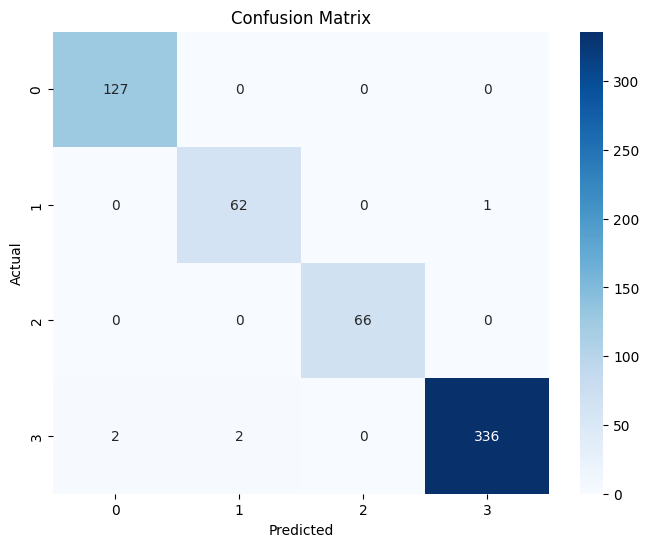

In [29]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [32]:
train_acc = rf.score(X_train_clean, y_train)

test_acc = rf.score(X_test_clean, y_test)

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)

Training Accuracy: 1.0
Testing Accuracy: 0.9916107382550335


In [33]:
X.columns

Index(['Time', 'Date', 'CarCount', 'BikeCount', 'BusCount', 'TruckCount',
       'Total', 'Hour', 'Day of the week_Monday', 'Day of the week_Saturday',
       'Day of the week_Sunday', 'Day of the week_Thursday',
       'Day of the week_Tuesday', 'Day of the week_Wednesday'],
      dtype='object')

In [34]:
import pandas as pd

new_sample = pd.DataFrame({
    'CarCount':[120],
    'BikeCount':[50],
    'BusCount':[10],
    'TruckCount':[5],
    'Total':[185],
    'Hour':[8],
    'Day_Monday':[1],
    'Day_Saturday':[0],
    'Day_Sunday':[0],
    'Day_Thursday':[0],
    'Day_Tuesday':[0],
    'Day_Wednesday':[0]
})

In [36]:
import pandas as pd


new_sample_clean = pd.DataFrame({
    'Date': [10],
    'CarCount': [120],
    'BikeCount': [50],
    'BusCount': [10],
    'TruckCount': [5],
    'Total': [185],
    'Hour': [8],
    'Day of the week_Monday': [1],
    'Day of the week_Saturday': [0],
    'Day of the week_Sunday': [0],
    'Day of the week_Thursday': [0],
    'Day of the week_Tuesday': [0],
    'Day of the week_Wednesday': [0]
})


new_sample_clean = new_sample_clean[X_train_clean.columns]

prediction = rf.predict(new_sample_clean)
print("Predicted Traffic Situation Class:", prediction)

Predicted Traffic Situation Class: [0]
